# **Project Name**    - **Paisabazaar Banking Fraud Analysis**


##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Member -** Yogesh Kumar


# **Project Summary -**


### **Paisabazaar Banking Fraud Analysis**  

Paisabazaar sits between a customer and a lender, and every loan it arranges ends in the same question: how likely is this person to repay? The platform already stores monthly financial records for its customers, but a record is not an answer. This project turns 100,000 monthly records covering 12,500 customers into a clear picture of what separates a **Good** credit score from a **Standard** one, and a Standard one from **Poor**.

The file contains 28 columns covering income, salary, bank accounts, credit cards, loans, interest rate, payment delays, outstanding debt, credit utilisation, credit mix, credit history and payment behaviour. The target column is `Credit_Score`, with three values: Good, Standard and Poor. Because each customer appears once for every month from 1 to 8, one row is one month of a person and not the whole person, and every count in this notebook is a count of monthly records.

The analysis starts by checking whether the file can be trusted, then moves to the three questions a lender actually asks. **How big is each credit group?** **Which columns separate the groups, and by how much?** **Which popular rules do not survive contact with the data?** The last question turned out to be the most useful one. Credit utilisation, the column most people expect to be a risk signal, moves by less than one percentage point between the Good, Standard and Poor groups, so the notebook reports it as a non-finding instead of inventing a rule from it.

### **Key Steps in the Analysis:**
- **Data Cleaning & Preparation:** Checked data types, converted count and age columns to whole numbers, separated `NM` ("not mentioned") from `No` in the payment column, and confirmed there are no missing values or duplicate rows.
- **Data Quality Audit:** Found 5,868 records with an age below 18, 11,824 records with a credit history longer than the customer's life, and 1,829 names that appear under more than one SSN.
- **Exploratory Data Analysis (EDA):** Ten charts, one column at a time first, then two columns, then many columns together.
- **Outlier Audit:** Applied the IQR rule to 15 numeric columns and kept the outliers on purpose, with the reasoning written into the notebook.
- **KPI Snapshot:** Five KPI blocks covering demographics, financial behaviour, loan performance, risk indicators and behavioural segments.
- **Credit Score Segmentation:** Compared the three score groups on income, interest rate, delay, debt, utilisation, credit mix, payment behaviour and occupation.

### **Key Insights Gained:**
- **82.2% of records are not Good** (53.2% Standard, 29.0% Poor), so the improvement opportunity sits in the middle group, which is also the biggest.
- **`Credit_Mix` is the strongest single column** at a correlation of +0.50, and customers with a Bad mix are 60.1% Poor against 1.5% Good.
- **Interest rate (−0.49) and payment delay (−0.43) separate the groups almost as well**, and both are already stored on every application.
- **Credit utilisation (+0.05) and EMI (+0.02) carry no signal**, which is the opposite of what the usual 30%-utilisation rule would suggest.
- **Occupation explains nothing**: the best and the worst occupation differ by 7.1% on average income, while income inside a single occupation varies by 11 times that.
- **The only fraud-shaped pattern is in the identity columns**: 18.1% of names appear with between 2 and 6 SSNs, covering 33.6% of the file.

# **GitHub Link -**


**[Paisabazaar Credit Score Analysis](https://github.com/Yogesh2201)**

# **Problem Statement**


**Paisabazaar** works with lenders who approve or reject a loan on the strength of a **credit score**, and a score that is read wrongly is expensive in both directions. A customer who would have repaid is rejected and the platform loses a good loan. A customer who will not repay is approved and the lender takes the loss.

The file available for this analysis holds **100,000 monthly records** for **12,500 customers**, but it arrives with no analysis attached. Three questions are open:

- **How large is each credit group?** A model, a campaign or a collection plan is worth different amounts depending on whether the Good group is 18% of the file or 50%.
- **Which columns actually separate the groups?** Some columns are known to matter, some are assumed to matter, and the two are not the same list.
- **Can the data be trusted?** The file contains records with an age below 18, credit histories longer than the customer's life, and 1,829 names that appear under more than one SSN.

Without answers, three costs follow:

- **Rules are built on assumptions** instead of on evidence, and a rule that fires on 60% of the file while separating nothing is worse than no rule.
- **Lending decisions are taken on a single month** of a customer, even though the score is not stable: 58.3% of the customers change score at least once in eight months.
- **Identity problems are never checked**, because the columns that would expose them look like harmless reference data and are the first ones dropped.


#### **Define Your Business Objective?**



The objective is to turn the monthly records into **a small set of decisions Paisabazaar can act on**:

- **Quantify the three credit groups** so the size of the improvement opportunity is known before any product work begins.
- **Rank the columns by how strongly they separate the groups**, so the business knows which four or five fields deserve attention and which can be left alone.
- **Test inherited beliefs against the data**, in particular the common rule that credit utilisation above 30% means risk.
- **Surface the data-quality and identity problems** that would quietly invalidate any scoring model built on this file.
- **Leave a monitoring baseline** that can be tracked month by month, using the same numbers on every refresh.

The output of this notebook is an **EDA and a KPI baseline**, not a trained model. Every number here is measured directly from the file, so the conclusions can be reproduced by anyone holding the same CSV.



# ***Let's Begin !***


## ***1. Know Your Data***


### Import Libraries


In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

### Dataset Loading


In [ ]:
# Load the dataset from the public URL directly
import pandas as pd

public_url = 'https://raw.githubusercontent.com/Yogesh2201/paisabazaar-banking-fraud-analysis/main/dataset.csv'

df = pd.read_csv(public_url)
print('Rows and Columns:', df.shape)

Rows and Columns: (100000, 28)


### Dataset First View


In [ ]:
# First look at the data
print('First 5 rows')
display(df.head())

print('Last 5 rows')
display(df.tail())


First 5 rows


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


Last 5 rows


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
99995,155625,37932,4,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.663572,378.0,No,35.104023,24.028477,High_spent_Large_value_payments,479.866228,Poor
99996,155626,37932,5,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,40.565631,379.0,No,35.104023,24.028477,High_spent_Medium_value_payments,496.651610,Poor
99997,155627,37932,6,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor
99998,155628,37932,7,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard
99999,155629,37932,8,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.192463,382.0,No,35.104023,24.028477,High_spent_Medium_value_payments,393.673696,Poor


### Dataset Rows & Columns count


In [ ]:
# Shape of the dataset
print('Number of rows    :', df.shape[0])
print('Number of columns :', df.shape[1])


Number of rows    : 100000
Number of columns : 28


### Dataset Information


In [ ]:
# Information about the columns and their data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

#### Duplicate Values


In [ ]:
# Check for duplicate rows
print('Duplicate rows        :', df.duplicated().sum())
print('As a share of the file: {:.2f}%'.format(df.duplicated().mean() * 100))


Duplicate rows        : 0
As a share of the file: 0.00%


#### Missing Values/Null Values


In [ ]:
# Check for missing values in every column
missing = df.isnull().sum()

print('Total missing cells            :', missing.sum())
print('Columns with a missing value   :', (missing > 0).sum())
print('')

if missing.sum() == 0:
    print('No missing values in any column, so there is nothing to fill and no chart to draw.')
else:
    print(missing[missing > 0].sort_values(ascending=False))
    plt.figure(figsize=(11, 3))
    sns.heatmap(df.isnull().iloc[:2000].T, cbar=False, cmap='coolwarm')
    plt.title('Missing Values (first 2,000 rows)')
    plt.xlabel('Row')
    plt.show()


Total missing cells            : 0
Columns with a missing value   : 0

No missing values in any column, so there is nothing to fill and no chart to draw.


#### How many customers are there?


In [ ]:
# The file has 100,000 rows, but how many actual customers?
print('Number of rows      :', len(df))
print('Number of customers :', df['Customer_ID'].nunique())
print('')
print('Rows per customer   :', df.groupby('Customer_ID').size().unique())
print('Months in the data  :', sorted(df['Month'].unique().tolist()))


Number of rows      : 100000
Number of customers : 12500

Rows per customer   : [8]
Months in the data  : [1, 2, 3, 4, 5, 6, 7, 8]


In [ ]:
# Does a customer keep the same credit score in every month?
scores_per_customer = df.groupby('Customer_ID')['Credit_Score'].nunique()

print(scores_per_customer.value_counts().sort_index())
same = (scores_per_customer == 1).mean() * 100
print('')
print('Customers with the same score in all 8 months : {:.1f}%'.format(same))
print('Customers whose score changes at least once   : {:.1f}%'.format(100 - same))


Credit_Score
1    5208
2    7262
3      30
Name: count, dtype: int64

Customers with the same score in all 8 months : 41.7%
Customers whose score changes at least once   : 58.3%


### What did you know about your dataset?

The file has **100,000 rows and 28 columns**. At first it looks like information about 100,000 different customers, but there are only **12,500 `Customer_ID` values** and each one appears exactly **8 times**, once for every month from 1 to 8. So these are monthly records of the same set of people, and not 100,000 separate customers. Every count in this notebook is therefore a count of monthly records, not of people.

There are **no missing values and no duplicate rows** in any column. That is good news, but it also means the usual "fill the blanks" step cannot be shown here. I still checked the columns one by one, because a file can have no nulls and still hold values that are wrong, and that is what happened with `Age` and `Credit_History_Age` in Section 3.

The target column is `Credit_Score`, with three values: **Standard 53,174 records (53.2%)**, **Poor 28,998 (29.0%)** and **Good 17,828 (17.8%)**. The label is not fixed for a customer. Only **41.7%** of the customers keep the same score in all 8 months, so **58.3%** of them change it at least once. I kept this in mind while reading the charts, because one row is one month of a person and not the whole person.

The columns fall into a few clear groups:

- **Personal details:** `Age`, `Occupation`, `Annual_Income`, `Monthly_Inhand_Salary`
- **Accounts and credit:** `Num_Bank_Accounts`, `Num_Credit_Card`, `Credit_Mix`, `Credit_Utilization_Ratio`
- **Loans and debt:** `Num_of_Loan`, `Type_of_Loan`, `Outstanding_Debt`, `Total_EMI_per_month`
- **Repayment behaviour:** `Delay_from_due_date`, `Num_of_Delayed_Payment`, `Payment_of_Min_Amount`, `Payment_Behaviour`
- **History and identity:** `Credit_History_Age`, `Name`, `SSN`
- **Target:** `Credit_Score`


## ***2. Understanding Your Variables***


In [ ]:
# List of all the columns
df.columns


Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

In [ ]:
# Describe the columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
ID,100000.0,8.063150e+04,4.330149e+04,5634.000000,4.313275e+04,8.063150e+04,1.181302e+05,1.556290e+05
Customer_ID,100000.0,2.598267e+04,1.434054e+04,1006.000000,1.366450e+04,2.577700e+04,3.838500e+04,5.099900e+04
Month,100000.0,4.500000e+00,2.291299e+00,1.000000,2.750000e+00,4.500000e+00,6.250000e+00,8.000000e+00
Age,100000.0,3.331634e+01,1.076481e+01,14.000000,2.400000e+01,3.300000e+01,4.200000e+01,5.600000e+01
SSN,100000.0,5.004617e+08,2.908267e+08,81349.000000,2.451686e+08,5.006886e+08,7.560027e+08,9.999934e+08
Annual_Income,100000.0,5.050512e+04,3.829942e+04,7005.930000,1.934297e+04,3.699971e+04,7.168347e+04,1.799873e+05
Monthly_Inhand_Salary,100000.0,4.197271e+03,3.186432e+03,303.645417,1.626594e+03,3.095905e+03,5.957715e+03,1.520463e+04
Num_Bank_Accounts,100000.0,5.368820e+00,2.593314e+00,0.000000,3.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Num_Credit_Card,100000.0,5.533570e+00,2.067098e+00,0.000000,4.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Interest_Rate,100000.0,1.453208e+01,8.741330e+00,1.000000,7.000000e+00,1.300000e+01,2.000000e+01,3.400000e+01


### Check Unique Values for each variable.


In [ ]:
# How many unique values each column has
df.nunique().sort_values()


,0
Payment_of_Min_Amount,3
Credit_Score,3
Credit_Mix,3
Payment_Behaviour,6
Month,8
Num_of_Loan,10
Num_Bank_Accounts,12
Num_Credit_Card,12
Occupation,15
Num_Credit_Inquiries,18


### Variables Description

| Category | Columns |
|---|---|
| **Identifiers** | `ID`, `Customer_ID`, `Name`, `SSN` |
| **Demographics** | `Age`, `Occupation`, `Month` |
| **Income** | `Annual_Income`, `Monthly_Inhand_Salary` |
| **Banking & credit** | `Num_Bank_Accounts`, `Num_Credit_Card`, `Interest_Rate`, `Credit_Mix` |
| **Loans** | `Num_of_Loan`, `Type_of_Loan`, `Total_EMI_per_month` |
| **Repayment** | `Delay_from_due_date`, `Num_of_Delayed_Payment`, `Payment_of_Min_Amount`, `Payment_Behaviour` |
| **Credit profile** | `Outstanding_Debt`, `Credit_Utilization_Ratio`, `Credit_History_Age`, `Changed_Credit_Limit`, `Num_Credit_Inquiries` |
| **Balance & savings** | `Amount_invested_monthly`, `Monthly_Balance` |
| **Target** | `Credit_Score` (Good / Standard / Poor) |

| Column | Meaning | Type |
|---|---|---|
| `ID` | Row number | Number |
| `Customer_ID` | ID of the customer (12,500 customers) | Number |
| `Month` | Month of the record, 1 to 8 | Number |
| `Name` | Customer name | Text |
| `Age` | Age in years | Number |
| `SSN` | Social Security Number | Number |
| `Occupation` | Job of the customer (15 types) | Text |
| `Annual_Income` | Yearly income | Number |
| `Monthly_Inhand_Salary` | Monthly take-home salary | Number |
| `Num_Bank_Accounts` | Number of bank accounts | Number |
| `Num_Credit_Card` | Number of credit cards | Number |
| `Interest_Rate` | Interest rate on the loan | Number |
| `Num_of_Loan` | Number of loans | Number |
| `Type_of_Loan` | Which loans (Home Loan, Auto Loan and so on) | Text |
| `Delay_from_due_date` | Average number of days the payment is late | Number |
| `Num_of_Delayed_Payment` | How many payments were late | Number |
| `Changed_Credit_Limit` | Change in the credit limit | Number |
| `Num_Credit_Inquiries` | How many times the customer asked for new credit | Number |
| `Credit_Mix` | Type of credit used: `Bad`, `Standard` or `Good` | Text |
| `Outstanding_Debt` | Money still owed | Number |
| `Credit_Utilization_Ratio` | How much of the credit limit is being used | Number |
| `Credit_History_Age` | How long the customer has had credit, in months | Number |
| `Payment_of_Min_Amount` | Whether only the minimum is paid: `Yes`, `No` or `NM` | Text |
| `Total_EMI_per_month` | Total EMI paid in a month | Number |
| `Amount_invested_monthly` | Money invested every month | Number |
| `Payment_Behaviour` | Spending pattern (spend level and payment size) | Text |
| `Monthly_Balance` | Balance left at the end of the month | Number |
| `Credit_Score` | **Target**: `Good`, `Standard` or `Poor` | Text |


## ***3. Data Wrangling***


### Data Wrangling Code


In [ ]:
# Keep the identity columns aside before the main data is cleaned.
# They are not analysis columns, but they are the only place where an
# identity problem can show up, so they are needed later for Chart 10.
identity = df[['Customer_ID', 'Name', 'SSN']].drop_duplicates()

print('Identity records saved :', len(identity))

# 1. Drop ID. It is only a row number.
df.drop(columns=['ID'], inplace=True)

# 2. These columns are counts and an age, so they should be whole numbers.
int_cols = ['Age', 'Num_Bank_Accounts', 'Num_Credit_Card',
            'Num_of_Loan', 'Num_Credit_Inquiries', 'Num_of_Delayed_Payment']
for col in int_cols:
    df[col] = df[col].astype(int)

# 3. NM in Payment_of_Min_Amount means "not mentioned", which is not the same
#    as No. It is renamed to Unknown so it stays a separate group.
df['Payment_of_Min_Amount'] = df['Payment_of_Min_Amount'].replace('NM', 'Unknown')

# 4. Number versions of the two text columns, needed for the heatmap.
#    The original text columns are kept as they are.
df['Credit_Score_Level'] = df['Credit_Score'].map({'Poor': 1, 'Standard': 2, 'Good': 3})
df['Credit_Mix_Num'] = df['Credit_Mix'].map({'Bad': 0, 'Standard': 1, 'Good': 2})

# 5. Ratios built from columns that already exist.
df['Income_per_Account'] = df['Annual_Income'] / df['Num_Bank_Accounts'].clip(lower=1)
df['Debt_to_Income'] = df['Outstanding_Debt'] / df['Annual_Income'].clip(lower=1)
df['EMI_Burden_Ratio'] = df['Total_EMI_per_month'] / df['Monthly_Inhand_Salary'].clip(lower=1)

print('Columns after wrangling :', df.shape[1])
print('Rows                    :', df.shape[0])
df.head()


Identity records saved : 12500
Columns after wrangling : 32
Rows                    : 100000


,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,...,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Credit_Score_Level,Credit_Mix_Num,Income_per_Account,Debt_to_Income,EMI_Burden_Ratio
0,3392,1,Aaron Maashoh,23,821000265.0,Scientist,19114.12,1824.843333,3,4,...,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good,3,2,6371.373333,0.042376,0.027167
1,3392,2,Aaron Maashoh,23,821000265.0,Scientist,19114.12,1824.843333,3,4,...,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good,3,2,6371.373333,0.042376,0.027167
2,3392,3,Aaron Maashoh,23,821000265.0,Scientist,19114.12,1824.843333,3,4,...,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good,3,2,6371.373333,0.042376,0.027167
3,3392,4,Aaron Maashoh,23,821000265.0,Scientist,19114.12,1824.843333,3,4,...,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good,3,2,6371.373333,0.042376,0.027167
4,3392,5,Aaron Maashoh,23,821000265.0,Scientist,19114.12,1824.843333,3,4,...,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good,3,2,6371.373333,0.042376,0.027167


In [ ]:
# Duplicates and missing values, checked again after the conversions
print('Missing cells :', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())

df.drop_duplicates(inplace=True)
df.dropna(inplace=True)

print('')
print('Shape after cleaning :', df.shape)


Missing cells : 0
Duplicate rows: 0

Shape after cleaning : (100000, 32)


In [ ]:
# Checks after cleaning
print('Payment_of_Min_Amount values :', df['Payment_of_Min_Amount'].unique())
print('Credit_Score values          :', df['Credit_Score'].unique())
print('Credit_Mix values            :', df['Credit_Mix'].unique())
print('Minimum age                  :', df['Age'].min())
print('Maximum age                  :', df['Age'].max())
print('Any score left unmapped      :', df['Credit_Score_Level'].isnull().sum())


Payment_of_Min_Amount values : ['No' 'Unknown' 'Yes']
Credit_Score values          : ['Good' 'Standard' 'Poor']
Credit_Mix values            : ['Good' 'Standard' 'Bad']
Minimum age                  : 14
Maximum age                  : 56
Any score left unmapped      : 0


In [ ]:
# Data quality checks: how many rows describe something impossible?
under_18 = (df['Age'] < 18).sum()
history_too_long = (df['Credit_History_Age'] > df['Age'] * 12).sum()

print('Rows where the age is below 18                       :', under_18)
print('Rows where the credit history is longer than the age :', history_too_long)
print('')
print('As a share of the file:')
print('  age below 18            : {:.2f}%'.format(under_18 / len(df) * 100))
print('  history longer than age : {:.2f}%'.format(history_too_long / len(df) * 100))
print('')
print('Youngest age        :', df['Age'].min())
print('Longest history     :', df['Credit_History_Age'].max(), 'months')
print('Age of that customer:', df.loc[df['Credit_History_Age'].idxmax(), 'Age'], 'years')


Rows where the age is below 18                       : 5868
Rows where the credit history is longer than the age : 11824

As a share of the file:
  age below 18            : 5.87%
  history longer than age : 11.82%

Youngest age        : 14
Longest history     : 404.0 months
Age of that customer: 25 years


#### Checking Outliers using IQR

Before drawing any charts I checked the numeric columns for outliers. The IQR rule is easy to apply: take the first quartile (Q1, the 25th percentile) and the third quartile (Q3, the 75th percentile). The difference between them is the IQR. Any value below `Q1 - 1.5 * IQR` or above `Q3 + 1.5 * IQR` is counted as an outlier.


In [ ]:
# Outlier check using the IQR method
num_cols = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
            'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date',
            'Num_of_Delayed_Payment', 'Num_Credit_Inquiries', 'Outstanding_Debt',
            'Credit_Utilization_Ratio', 'Total_EMI_per_month',
            'Amount_invested_monthly', 'Monthly_Balance']

rows = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()

    rows.append([col, round(q1, 2), round(q3, 2), round(iqr, 2),
                 round(lower, 2), round(upper, 2), count,
                 round(count / len(df) * 100, 2)])

outliers = pd.DataFrame(rows, columns=['Column', 'Q1', 'Q3', 'IQR',
                                       'Lower bound', 'Upper bound',
                                       'Outliers', '% of rows'])
outliers.sort_values('Outliers', ascending=False)


,Column,Q1,Q3,IQR,Lower bound,Upper bound,Outliers,% of rows
14,Monthly_Balance,267.62,463.22,195.60,-25.78,756.62,7400,7.40
10,Outstanding_Debt,566.07,1945.96,1379.89,-1503.76,4015.80,5272,5.27
12,Total_EMI_per_month,29.27,147.39,118.12,-147.92,324.58,5044,5.04
13,Amount_invested_monthly,27.96,71.30,43.34,-37.05,136.30,4464,4.46
7,Delay_from_due_date,10.00,28.00,18.00,-17.00,55.00,4002,4.00
2,Monthly_Inhand_Salary,1626.59,5957.72,4331.12,-4870.09,12454.40,2017,2.02
1,Annual_Income,19342.97,71683.47,52340.50,-59167.77,150194.22,2000,2.00
9,Num_Credit_Inquiries,3.00,8.00,5.00,-4.50,15.50,787,0.79
11,Credit_Utilization_Ratio,28.05,36.50,8.44,15.39,49.16,4,0.00
6,Num_of_Loan,2.00,5.00,3.00,-2.50,9.50,0,0.00


In [ ]:
# How many rows are affected if every column is counted together?
flag = pd.Series(False, index=df.index)
for i in range(len(outliers)):
    col = outliers.loc[i, 'Column']
    low = outliers.loc[i, 'Lower bound']
    high = outliers.loc[i, 'Upper bound']
    flag = flag | (df[col] < low) | (df[col] > high)

print('Rows with at least one outlier :', flag.sum())
print('As a share of the file         : {:.2f}%'.format(flag.mean() * 100))
print('')
print('Columns with no outliers at all:')
print(', '.join(outliers[outliers['Outliers'] == 0]['Column']))
print('')
print('Columns with the most outliers:')
top = outliers.sort_values('Outliers', ascending=False).head(3)
for i in range(3):
    print('  {:<24} {:>6} rows  ({:.1f}%)'.format(top.iloc[i]['Column'],
                                                 top.iloc[i]['Outliers'],
                                                 top.iloc[i]['% of rows']))


Rows with at least one outlier : 22919
As a share of the file         : 22.92%

Columns with no outliers at all:
Age, Num_Bank_Accounts, Num_Credit_Card, Interest_Rate, Num_of_Loan, Num_of_Delayed_Payment

Columns with the most outliers:
  Monthly_Balance            7400 rows  (7.4%)
  Outstanding_Debt           5272 rows  (5.3%)
  Total_EMI_per_month        5044 rows  (5.0%)


#### What I did about the outliers

I did not remove them, and I did not replace them with the quartile limits. There are two reasons.

The first is the size of the problem. **22,919 rows (22.9%) have at least one outlier**, which is almost a quarter of the file. Deleting a quarter of the data to fix a few large values would cost more than it gains, and it would change every average later in the notebook.

The second reason is what the outliers actually are. **Every lower bound in the table is a negative number** (for example −59,167 for `Annual_Income`), so nothing is being flagged as "too small". All the outliers are on the high side, and a customer with a high income or a large outstanding debt is not a data entry error. That is a customer with a bigger loan. Removing those rows would delete the customers a lender cares about most.

The third reason is practical. The charts below are boxplots, boxplots draw the outliers as dots, and the counts are printed in the table above. So the outliers are **reported** rather than hidden, and a reader can see exactly how many there are and in which column.


### What all manipulations have you done and insights you found?

**What I did**

1. I kept a separate table with `Customer_ID`, `Name` and `SSN` (12,500 rows) before cleaning the main data. These columns are not analysis fields, but they are the only place where an identity problem can appear, and I needed them for Chart 10.
2. I dropped `ID`, because it is just a row number and it carries no information about the customer.
3. I converted `Age`, `Num_Bank_Accounts`, `Num_Credit_Card`, `Num_of_Loan`, `Num_Credit_Inquiries` and `Num_of_Delayed_Payment` from decimal to whole numbers. These are counts and an age, so 23.0 should be 23. I checked first that none of them held a fraction.
4. I changed `NM` to `Unknown` in `Payment_of_Min_Amount`. `NM` means "not mentioned", and folding it into `No` would move 12,007 records into a group that says the customer actively refused to pay the minimum, which is not what the file says.
5. I made `Credit_Score_Level` (1, 2, 3) and `Credit_Mix_Num` (0, 1, 2) so the two text columns can go into a correlation heatmap. The original text columns are untouched and every chart still uses the text.
6. I added three ratios: `Income_per_Account`, `Debt_to_Income` and `EMI_Burden_Ratio`. Each one is a division of two columns that were already there, and I clipped the denominator at 1 so that a zero cannot produce an infinity.
7. I checked duplicates and missing values again after the conversions, because `astype(int)` would have failed silently on a null if one existed. Both are still zero.
8. I applied the IQR rule to 15 numeric columns and decided to keep the outliers, for the reasons written above.

**What I found**

- The data is already clean in the narrow sense: **no missing values and no duplicate rows**, so there was nothing to fill in or remove.
- There are **100,000 rows but only 12,500 customers**, each appearing 8 times. A count in any chart is a count of monthly records, not of people.
- **58.3% of customers change their credit score at least once** in the 8 months, so the score is not a permanent label and one month is not a verdict.
- **22.9% of rows have an outlier in at least one column**, all of them on the high side, and **6 of the 15 numeric columns have none at all**.
- Two values cannot be true. **5,868 rows have an age below 18**, and the youngest customer is **14**. **11,824 rows have a credit history longer than the person has been alive**; the longest history is 404 months (33.7 years) and that customer is 25. Both are reported here and in Chart 2 instead of being deleted, so that the reader knows about them.
- **`Annual_Income` and `Monthly_Inhand_Salary` are the same column in two units**: their correlation is 0.998, so only one of them is needed in any model.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

The charts are in three groups, and the KPI blocks come first so the numbers are on the page before the pictures.

- **KPI 1 to 5**: the headline numbers for the business
- **Chart 1 to 4**: one column at a time (univariate)
- **Chart 5 to 8**: two columns together (bivariate)
- **Chart 9 to 10**: many columns together (multivariate)

For every chart I answered the same three questions.


### KPI Snapshot - The Numbers Before the Charts

These are the numbers a business dashboard would show on its first screen. They are printed rather than charted, because a KPI that is a single value is easier to read as a number than as a bar.


#### KPI 1 - Customer Demographics


In [ ]:
print('=' * 64)
print('  KPI 1 : CUSTOMER DEMOGRAPHICS')
print('=' * 64)

print('Average age          : {:.2f} years'.format(df['Age'].mean()))
print('Median age           : {:.1f} years'.format(df['Age'].median()))
print('Age range            : {} to {} years'.format(df['Age'].min(), df['Age'].max()))
print('Unique customers     : {:,}'.format(df['Customer_ID'].nunique()))
print('Unique names         : {:,}'.format(df['Name'].nunique()))
print('')

print('Top 5 occupations')
occ = df['Occupation'].value_counts()
for name, count in occ.head(5).items():
    print('  {:<16s} {:>6,}  ({:.1f}%)'.format(name, count, count / len(df) * 100))
print('')

print('Income groups')
# The last edge is infinity so that the bands stay monotonic whatever the
# maximum income happens to be. No customer earns above 200K in this file.
bins = [0, 25000, 50000, 100000, 200000, float('inf')]
labels = ['Low (<25K)', 'Lower-Mid (25-50K)', 'Mid (50-100K)',
          'Upper-Mid (100-200K)', 'High (>200K)']
df['Income_Group'] = pd.cut(df['Annual_Income'], bins=bins, labels=labels,
                            include_lowest=True)
print(df['Income_Group'].value_counts().sort_index().to_string())
print('Highest income in the file : {:,.2f}'.format(df['Annual_Income'].max()))


  KPI 1 : CUSTOMER DEMOGRAPHICS
Average age          : 33.32 years
Median age           : 33.0 years
Age range            : 14 to 56 years
Unique customers     : 12,500
Unique names         : 10,128

Top 5 occupations
  Lawyer            7,096  (7.1%)
  Engineer          6,864  (6.9%)
  Architect         6,824  (6.8%)
  Mechanic          6,776  (6.8%)
  Accountant        6,744  (6.7%)

Income groups
Income_Group
Low (<25K)              33480
Lower-Mid (25-50K)      27296
Mid (50-100K)           26496
Upper-Mid (100-200K)    12728
High (>200K)                0
Highest income in the file : 179,987.28


#### KPI 2 - Financial Behaviour


In [ ]:
print('=' * 64)
print('  KPI 2 : FINANCIAL BEHAVIOUR')
print('=' * 64)

print('Average annual income      : {:>12,.2f}'.format(df['Annual_Income'].mean()))
print('Median annual income       : {:>12,.2f}'.format(df['Annual_Income'].median()))
print('Average monthly in-hand    : {:>12,.2f}'.format(df['Monthly_Inhand_Salary'].mean()))
print('Average outstanding debt   : {:>12,.2f}'.format(df['Outstanding_Debt'].mean()))
print('Average credit utilization : {:>12.2f}%'.format(df['Credit_Utilization_Ratio'].mean()))
print('Average debt-to-income     : {:>12.4f}'.format(df['Debt_to_Income'].mean()))
print('Average bank accounts      : {:>12.2f}'.format(df['Num_Bank_Accounts'].mean()))
print('Average credit cards       : {:>12.2f}'.format(df['Num_Credit_Card'].mean()))
print('Average income per account : {:>12,.2f}'.format(df['Income_per_Account'].mean()))


  KPI 2 : FINANCIAL BEHAVIOUR
Average annual income      :    50,505.12
Median annual income       :    36,999.71
Average monthly in-hand    :     4,197.27
Average outstanding debt   :     1,426.22
Average credit utilization :        32.29%
Average debt-to-income     :       0.0607
Average bank accounts      :         5.37
Average credit cards       :         5.53
Average income per account :    16,075.67


#### KPI 3 - Loan and Credit Performance


In [ ]:
print('=' * 64)
print('  KPI 3 : LOAN AND CREDIT PERFORMANCE')
print('=' * 64)

print('Average loans per customer   : {:>10.2f}'.format(df['Num_of_Loan'].mean()))
print('Average interest rate        : {:>10.2f}%'.format(df['Interest_Rate'].mean()))
print('Average EMI per month        : {:>10,.2f}'.format(df['Total_EMI_per_month'].mean()))
print('Average monthly investment   : {:>10,.2f}'.format(df['Amount_invested_monthly'].mean()))
print('Average credit history       : {:>10.1f} months ({:.1f} years)'.format(
      df['Credit_History_Age'].mean(), df['Credit_History_Age'].mean() / 12))
print('Average EMI burden ratio     : {:>10.4f} ({:.2f}% of salary)'.format(
      df['EMI_Burden_Ratio'].mean(), df['EMI_Burden_Ratio'].mean() * 100))
print('Average monthly balance      : {:>10,.2f}'.format(df['Monthly_Balance'].mean()))


  KPI 3 : LOAN AND CREDIT PERFORMANCE
Average loans per customer   :       3.53
Average interest rate        :      14.53%
Average EMI per month        :     107.70
Average monthly investment   :      55.10
Average credit history       :      221.2 months (18.4 years)
Average EMI burden ratio     :     0.0298 (2.98% of salary)
Average monthly balance      :     392.70


#### KPI 4 - Risk and Fraud Indicators


In [ ]:
print('=' * 64)
print('  KPI 4 : RISK AND FRAUD INDICATORS')
print('=' * 64)

print('Average delayed payments        : {:>7.2f}'.format(df['Num_of_Delayed_Payment'].mean()))
print('Average delay from due date     : {:>7.2f} days'.format(df['Delay_from_due_date'].mean()))
print('Maximum delay from due date     : {:>7.0f} days'.format(df['Delay_from_due_date'].max()))
print('Records with a credit inquiry   : {:>7.1f}%'.format((df['Num_Credit_Inquiries'] > 0).mean() * 100))
print('Records with a changed limit    : {:>7.1f}%'.format((df['Changed_Credit_Limit'] != 0).mean() * 100))
print('Records paying only the minimum : {:>7.1f}%'.format((df['Payment_of_Min_Amount'] == 'Yes').mean() * 100))
print('')

print('Credit score distribution')
cs = df['Credit_Score'].value_counts()
for label in ['Good', 'Standard', 'Poor']:
    count = cs[label]
    bar = '#' * int(count / len(df) * 100)
    print('  {:<9s} {:>6,}  ({:>5.1f}%)  {}'.format(label, count,
                                                   count / len(df) * 100, bar))


  KPI 4 : RISK AND FRAUD INDICATORS
Average delayed payments        :   13.31
Average delay from due date     :   21.08 days
Maximum delay from due date     :      62 days
Records with a credit inquiry   :    92.8%
Records with a changed limit    :   100.0%
Records paying only the minimum :    52.3%

Credit score distribution
  Good      17,828  ( 17.8%)  #################
  Standard  53,174  ( 53.2%)  #####################################################
  Poor      28,998  ( 29.0%)  ############################


#### KPI 5 - Behavioural Segments


In [ ]:
print('=' * 64)
print('  KPI 5 : BEHAVIOURAL SEGMENTS')
print('=' * 64)

print('Payment behaviour')
pb = df['Payment_Behaviour'].value_counts()
for name, count in pb.items():
    print('  {:<34s} {:>6,}  ({:>5.1f}%)'.format(name, count, count / len(df) * 100))
print('')

print('Credit mix')
cm = df['Credit_Mix'].value_counts()
for name in ['Good', 'Standard', 'Bad']:
    count = cm[name]
    print('  {:<34s} {:>6,}  ({:>5.1f}%)'.format(name, count, count / len(df) * 100))
print('')

print('Payment of minimum amount')
pm = df['Payment_of_Min_Amount'].value_counts()
for name, count in pm.items():
    print('  {:<34s} {:>6,}  ({:>5.1f}%)'.format(name, count, count / len(df) * 100))


  KPI 5 : BEHAVIOURAL SEGMENTS
Payment behaviour
  Low_spent_Small_value_payments     28,616  ( 28.6%)
  High_spent_Medium_value_payments   19,738  ( 19.7%)
  High_spent_Large_value_payments    14,726  ( 14.7%)
  Low_spent_Medium_value_payments    14,399  ( 14.4%)
  High_spent_Small_value_payments    11,764  ( 11.8%)
  Low_spent_Large_value_payments     10,757  ( 10.8%)

Credit mix
  Good                               30,384  ( 30.4%)
  Standard                           45,848  ( 45.8%)
  Bad                                23,768  ( 23.8%)

Payment of minimum amount
  Yes                                52,326  ( 52.3%)
  No                                 35,667  ( 35.7%)
  Unknown                            12,007  ( 12.0%)


### Chart - 1 **Number of Records by Occupation (Univariate)**


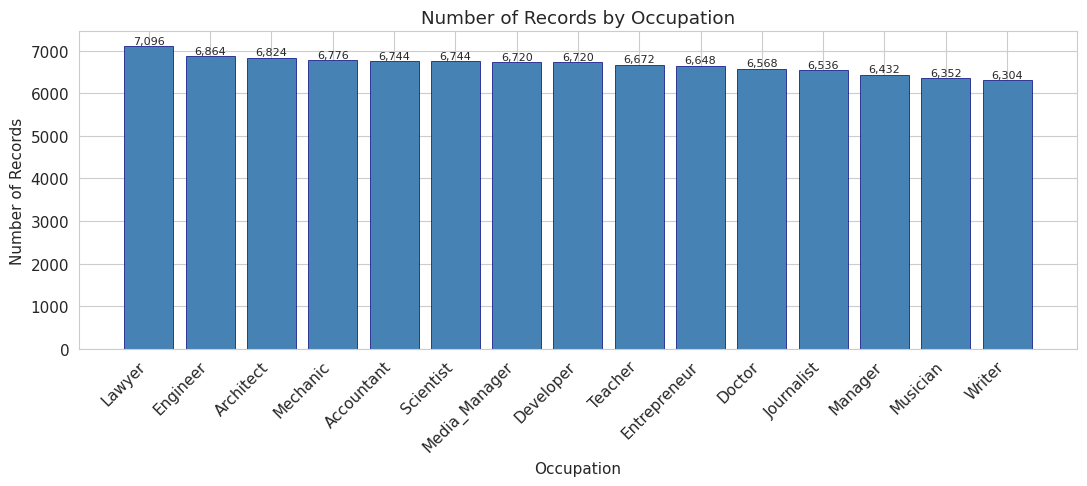

Occupation
Lawyer           7096
Engineer         6864
Architect        6824
Mechanic         6776
Accountant       6744
Scientist        6744
Media_Manager    6720
Developer        6720
Teacher          6672
Entrepreneur     6648
Doctor           6568
Journalist       6536
Manager          6432
Musician         6352
Writer           6304
Name: count, dtype: int64

Largest  : Lawyer 7096
Smallest : Writer 6304
Gap      : 792 records
Gap as % of the smallest : 12.6%


In [ ]:
# Chart - 1 : how many records each occupation has
occ_counts = df['Occupation'].value_counts()

plt.figure(figsize=(11, 5))
bars = plt.bar(occ_counts.index, occ_counts.values,
               color='steelblue', edgecolor='navy', linewidth=0.5)
plt.title('Number of Records by Occupation')
plt.xlabel('Occupation')
plt.ylabel('Number of Records')
plt.xticks(rotation=45, ha='right')

for bar, value in zip(bars, occ_counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 60, '{:,}'.format(value),
             ha='center', fontsize=8)

plt.tight_layout()
plt.show()

print(occ_counts)
print('')
print('Largest  :', occ_counts.idxmax(), occ_counts.max())
print('Smallest :', occ_counts.idxmin(), occ_counts.min())
print('Gap      :', occ_counts.max() - occ_counts.min(), 'records')
print('Gap as % of the smallest : {:.1f}%'.format(
      (occ_counts.max() - occ_counts.min()) / occ_counts.min() * 100))


#### **1. Why did you pick the specific chart?**

Occupation is a category with 15 values, so a bar chart is the direct choice: the height of the bar is the count, and the bars can be compared without a legend. I kept raw counts instead of percentages on purpose, because all 15 values sit between 6.3% and 7.1% of the file, and a percentage axis would make those differences look bigger than they are. The exact count is written above each bar so the reader does not have to estimate it from the height.

#### **2. What is/are the insight(s) found from the chart?**

- `Lawyer` is the largest group with 7,096 records (7.1%), followed by `Engineer` (6,864), `Architect` (6,824), `Mechanic` (6,776) and `Scientist` (6,744).
- `Writer` is the smallest with 6,304 records (6.3%), then `Musician` (6,352), `Manager` (6,432), `Journalist` (6,536) and `Doctor` (6,568).
- The whole gap between the largest and the smallest occupation is **792 records**, which is 12.6% of the smallest group.
- Because each customer appears 8 times, these are record counts. In customer terms there are about **788 to 887 unique customers** per occupation, so the 15 groups are close to equal.
- No occupation is close to a majority. The largest one is **7.1% of the file**.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

In a good way, the even spread means **one product design covers the whole file**. There is no occupation that deserves its own product, its own income band or its own campaign budget, which also saves the cost of maintaining 15 separate campaigns. Marketing can rotate through the segments instead of concentrating on one.

The negative side is that **any occupation-led growth plan is capped at 7% of the file**. A "target lawyers" campaign reaches 7,096 records, and if the same offer is aimed at writers it reaches almost the same number. So occupation is a poor basis for choosing where to grow, and the difference between the best and the worst segment (12.6%) is small enough that a good offer will outperform it. The useful reading is that a chart with almost equal bars is a result, and the result is "do not segment on this column".


### Chart - 2 **Distribution of Age (Univariate)**


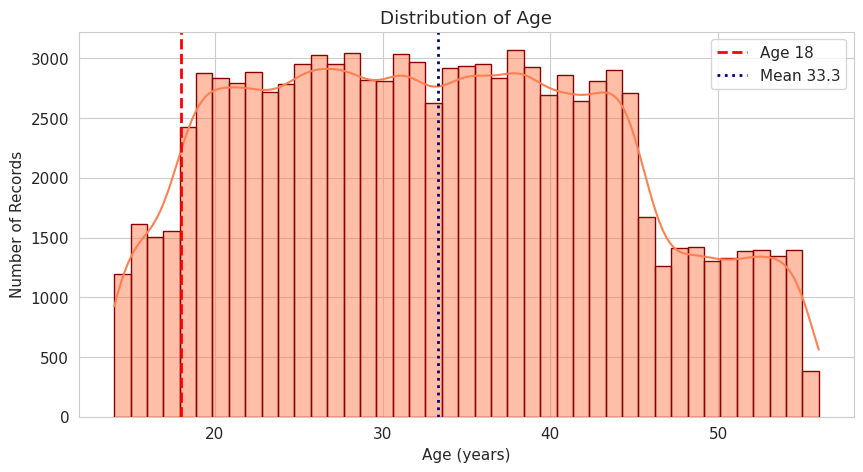

Minimum age            : 14
Maximum age            : 56
Average age            : 33.32
Median age             : 33.0
Skewness               : 0.156
Middle half (Q1 to Q3) : 24 to 42
Records below 18       : 5868
As a share of the file : 5.87%


In [ ]:
# Chart - 2 : distribution of age
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Age', bins=43, kde=True, color='coral', edgecolor='darkred')
plt.axvline(18, color='red', linestyle='--', linewidth=2, label='Age 18')
plt.axvline(df['Age'].mean(), color='navy', linestyle=':', linewidth=2,
            label='Mean {:.1f}'.format(df['Age'].mean()))
plt.title('Distribution of Age')
plt.xlabel('Age (years)')
plt.ylabel('Number of Records')
plt.legend()
plt.show()

print('Minimum age            :', df['Age'].min())
print('Maximum age            :', df['Age'].max())
print('Average age            :', round(df['Age'].mean(), 2))
print('Median age             :', df['Age'].median())
print('Skewness               :', round(df['Age'].skew(), 3))
print('Middle half (Q1 to Q3) : {:.0f} to {:.0f}'.format(df['Age'].quantile(0.25),
                                                       df['Age'].quantile(0.75)))
print('Records below 18       :', (df['Age'] < 18).sum())
print('As a share of the file : {:.2f}%'.format((df['Age'] < 18).mean() * 100))


#### **1. Why did you pick the specific chart?**

Age is a number, so a histogram is the right chart, and the `kde=True` line shows the overall shape without asking the reader to compare 43 bars. I set the number of bins to 43 so that every bin is exactly one year wide, and drew a red line at 18, the age at which a person can legally hold credit, because I wanted to see how many records fall below it.

#### **2. What is/are the insight(s) found from the chart?**

- Ages run from **14 to 56**.
- The average age is **33.32** and the median is **33**, so the two are almost identical. The skewness is **+0.156**, very close to zero, so the distribution is almost symmetric and no group of very young customers is dragging the average down.
- The middle half of the file is between **24 and 42**, which is the normal working age of a credit customer.
- **5,868 records (5.87%) are below 18**, and the youngest customer is **14**. A 14-year-old cannot hold a credit card or take a loan, so these rows cannot be real.
- Age has a correlation of only **+0.16** with the credit score (Chart 9), so it describes who the customer is much better than how they repay.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

For the business, the spread is comfortable. The customers sit between 24 and 42 with no second peak, so one normal set of loan products covers most of the file and there is no need for a special age-based product line.

The negative side is the 5,868 records below 18. They are 5.9% of the file, so they will not move an average much, but they will not survive a review. If someone from compliance opens this data, the first question will be why there are 14-year-olds with home loans. I did not delete them, because deleting them would hide the problem, but they must be removed or corrected at the source before the data is used for a lending decision. Age is also a protected characteristic in many jurisdictions, so it should be used for product eligibility and not as a scoring input.


### Chart - 3 **Distribution of Annual Income (Univariate)**


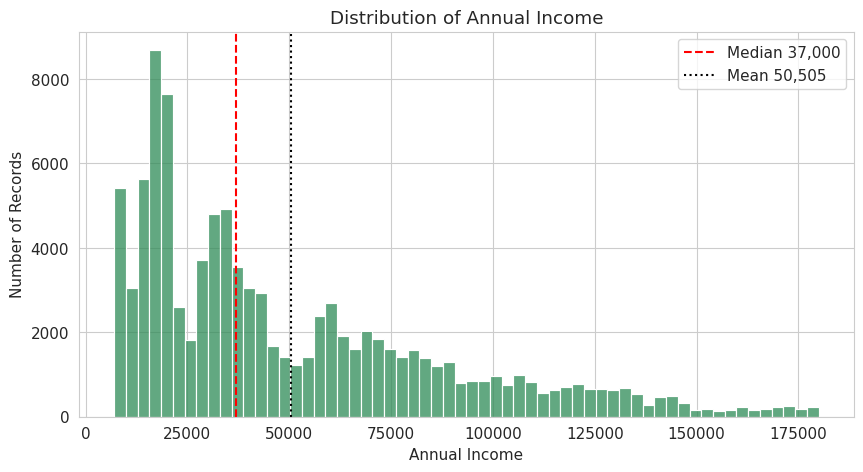

Minimum : 7005.93
Maximum : 179987.28
Mean    : 50505.12
Median  : 36999.71
Mean / Median : 1.37

Share between 10,000 and 50,000 : 55.11%
IQR upper limit for income      : 150,194.22
Records above that limit        : 2000


In [ ]:
# Chart - 3 : distribution of annual income
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Annual_Income', bins=60, color='seagreen')
plt.axvline(df['Annual_Income'].median(), color='red', linestyle='--',
            label='Median {:,.0f}'.format(df['Annual_Income'].median()))
plt.axvline(df['Annual_Income'].mean(), color='black', linestyle=':',
            label='Mean {:,.0f}'.format(df['Annual_Income'].mean()))
plt.title('Distribution of Annual Income')
plt.xlabel('Annual Income')
plt.ylabel('Number of Records')
plt.legend()
plt.show()

print('Minimum :', round(df['Annual_Income'].min(), 2))
print('Maximum :', round(df['Annual_Income'].max(), 2))
print('Mean    :', round(df['Annual_Income'].mean(), 2))
print('Median  :', round(df['Annual_Income'].median(), 2))
print('Mean / Median :', round(df['Annual_Income'].mean() / df['Annual_Income'].median(), 2))
print('')
print('Share between 10,000 and 50,000 : {:.2f}%'.format(
      ((df['Annual_Income'] >= 10000) & (df['Annual_Income'] <= 50000)).mean() * 100))

income_limit = outliers.loc[outliers['Column'] == 'Annual_Income', 'Upper bound'].values[0]
print('IQR upper limit for income      : {:,.2f}'.format(income_limit))
print('Records above that limit        :', (df['Annual_Income'] > income_limit).sum())


#### **1. Why did you pick the specific chart?**

Income has a long right tail, so a histogram shows the shape better than a single average. I drew both the median and the mean on the chart, because the distance between those two lines is the amount the high earners pull the average up, and that turned out to be the main point of this column.

#### **2. What is/are the insight(s) found from the chart?**

- The **median income is 36,999.71** and the **mean is 50,505.12**. The mean is **1.37 times** the median, so a small number of high earners is pulling the average up.
- The highest income is **179,987.28**, which is about **4.9 times the median**. This is the long tail.
- **55.1% of the records** fall between 10,000 and 50,000, which is one clear band.
- **2,000 records (2.0%)** sit above the IQR upper limit of **150,194.22**, which matches the visible tail.
- The minimum is 7,005.93, and there are no zero or negative incomes.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

The useful part is that more than half of the file sits in a single band, 10,000 to 50,000 a year. That is a well-defined group for a standard loan product, and the bank does not need many different designs to reach most customers.

The risk is in using the average. If loan sizes are planned from the mean income of 50,505, the bank assumes the normal customer earns about **13,505 more than the middle customer actually does (36,999.71)**, an overstatement of roughly 36%. Loans sized from that number will be too large for most borrowers, which raises the chance of default. For anything that describes a single customer the median is the safer number; the mean is only useful when adding up the whole portfolio. The 2,000 high earners should not be dropped, because they are the most profitable segment, but they should not define the product either.


### Chart - 4 **Distribution of Credit Score (Univariate)**


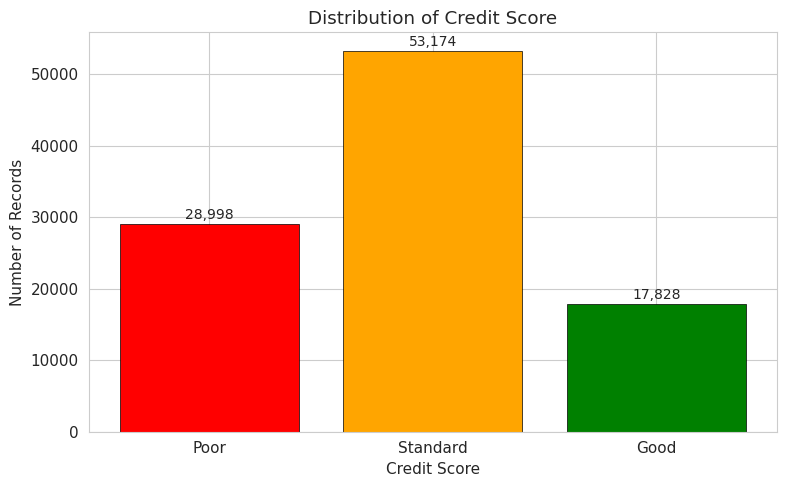

Credit_Score
Poor        28998
Standard    53174
Good        17828
Name: count, dtype: int64

Credit_Score
Poor        29.00
Standard    53.17
Good        17.83
Name: count, dtype: float64

Standard is 2.98 times bigger than Good
Share that is not Good : 82.17%


In [ ]:
# Chart - 4 : how many records are in each credit score
counts = df['Credit_Score'].value_counts().reindex(['Poor', 'Standard', 'Good'])

plt.figure(figsize=(8, 5))
bars = plt.bar(counts.index, counts.values, color=['red', 'orange', 'green'],
               edgecolor='black', linewidth=0.5)
plt.title('Distribution of Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Number of Records')

for bar, value in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 700, '{:,}'.format(value),
             ha='center', fontsize=10)

plt.tight_layout()
plt.show()

print(counts)
print('')
print((counts / len(df) * 100).round(2))
print('')
print('Standard is {:.2f} times bigger than Good'.format(counts['Standard'] / counts['Good']))
print('Share that is not Good : {:.2f}%'.format((counts['Poor'] + counts['Standard']) / len(df) * 100))


#### **1. Why did you pick the specific chart?**

A bar chart is the easiest way to show how many records are in each category, and with three groups it is easier to read than a pie, where the reader has to compare angles and look at a legend. The colours are fixed in the order Poor, Standard, Good, so the same colour means the same group in every chart in this notebook, and the count is written above each bar.

#### **2. What is/are the insight(s) found from the chart?**

- **Standard is the biggest group** with 53,174 records, which is **53.17%** of the file.
- **Poor is second** with 28,998 records (**29.00%**).
- **Good is the smallest** with 17,828 records (**17.83%**).
- Standard is almost **3 times bigger** than Good, so the groups are not balanced.
- **82.17% of the records are not Good**, which is the size of the improvement opportunity.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

In a good way, the Standard group is where a small improvement is worth the most, simply because there are so many people in it. Moving one record in ten out of Standard into Good is 5,317 records; the same rate applied to the Good group is only 1,783. So effort spent on the middle group returns about three times as much volume as effort spent on the top group.

The problem is the Good group. Only 17.8% of the records are Good, so the bank has a small number of low-risk customers to work with, and losing one of them costs more per customer than losing one from Standard. The other problem is statistical. Because 53.2% of the rows are Standard, a rule that always says "Standard" and learns nothing already scores 53.2% accuracy. Any model or scorecard built on this file has to be compared with that number and not with zero, or it will look good while doing nothing.


### Chart - 5 **Annual Income by Occupation (Bivariate)**


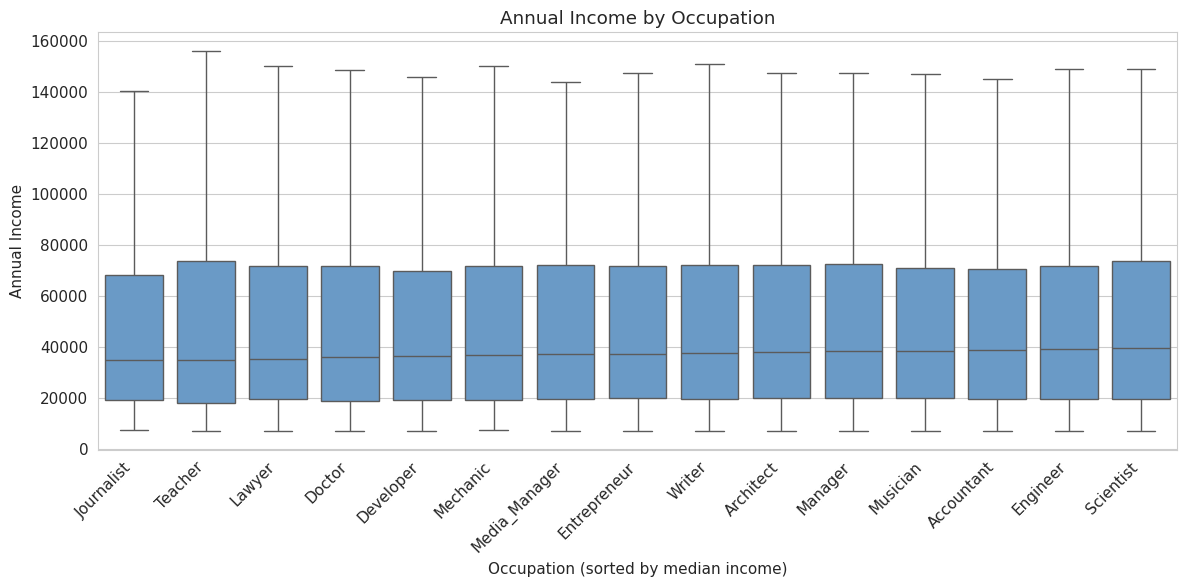

                 median      mean       std
Occupation                                 
Journalist     34742.74  48430.09  37897.79
Teacher        34954.88  49865.04  38637.98
Lawyer         35223.94  49594.22  38107.47
Doctor         35802.82  49517.75  38016.39
Developer      36422.83  50128.42  38594.86
Mechanic       36821.00  50095.11  38855.62
Media_Manager  36991.34  50618.44  38220.34
Entrepreneur   37360.94  50987.70  37607.76
Writer         37383.93  51047.66  38123.47
Architect      37827.77  51875.39  39252.58
Manager        38437.18  51466.77  38222.99
Musician       38486.44  51365.52  38597.48
Accountant     38624.06  50726.12  38375.21
Engineer       39072.07  50730.65  37893.58
Scientist      39487.82  51196.43  37926.47

Highest median : Scientist 39487.82
Lowest median  : Journalist 34742.74
Median gap     : 4745.08 (13.7% of the lowest)
Mean gap       : 3445.30 (7.1% of the lowest)
Average spread of income inside one occupation : 38288.67


In [ ]:
# Chart - 5 : annual income for each occupation
order_occ = df.groupby('Occupation')['Annual_Income'].median().sort_values().index.tolist()

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Occupation', y='Annual_Income', order=order_occ,
            color='#5b9bd5', showfliers=False)
plt.title('Annual Income by Occupation')
plt.xlabel('Occupation (sorted by median income)')
plt.ylabel('Annual Income')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

by_occ = df.groupby('Occupation')['Annual_Income'].agg(['median', 'mean', 'std']).sort_values('median')
print(by_occ.round(2).to_string())
print('')
print('Highest median :', by_occ['median'].idxmax(), round(by_occ['median'].max(), 2))
print('Lowest median  :', by_occ['median'].idxmin(), round(by_occ['median'].min(), 2))
print('Median gap     : {:.2f} ({:.1f}% of the lowest)'.format(
      by_occ['median'].max() - by_occ['median'].min(),
      (by_occ['median'].max() - by_occ['median'].min()) / by_occ['median'].min() * 100))
print('Mean gap       : {:.2f} ({:.1f}% of the lowest)'.format(
      by_occ['mean'].max() - by_occ['mean'].min(),
      (by_occ['mean'].max() - by_occ['mean'].min()) / by_occ['mean'].min() * 100))
print('Average spread of income inside one occupation : {:.2f}'.format(by_occ['std'].mean()))


#### **1. Why did you pick the specific chart?**

A boxplot is used when one number is compared across categories. It shows the median, the middle half of the data and the overall range at once, which a bar chart of averages would hide. I sorted the occupations by median income so the ranking is visible, and I hid the outlier dots with `showfliers=False` because Chart 3 already reports them and 15 sets of dots would bury the boxes.

#### **2. What is/are the insight(s) found from the chart?**

- The **median income runs from 34,743 (Journalist) to 39,488 (Scientist)**, a gap of **4,745**, which is 13.7% of the lowest median.
- On averages the gap is smaller still: 48,430 (Journalist) to 51,875 (Architect), a gap of **3,445**, or **7.1%**.
- The **average spread of income inside a single occupation is 38,289**, which is **8 times** the gap between the highest and the lowest median.
- The boxes almost completely overlap: the middle half of every occupation runs from roughly 18,000 to 73,000.
- `Doctor`, the occupation most people would expect at the top, has a median of 35,803, which is **below the overall median of 37,000**.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

The useful result here is a negative one, and it is worth stating clearly. Occupation is collected on the application, so it would be easy to build a rule on it, and this chart says do not. There is no occupation worth a separate product or a separate income band, which also saves the cost of maintaining 15 campaign variants.

The mistake would be to read the chart the other way and say "doctors earn the most, so lend them more". In this file the Doctor median is 35,803, below the overall median, and the gap between the best and the worst occupation is 7.1% of the average while incomes inside one occupation vary by around 38,000. Acting on that gap is the same as acting on noise, and it can point in the wrong direction. Occupation is fine for the wording of a marketing message, but it should not set a loan limit or a risk weight.


### Chart - 6 **Credit Utilization by Credit Score (Bivariate)**


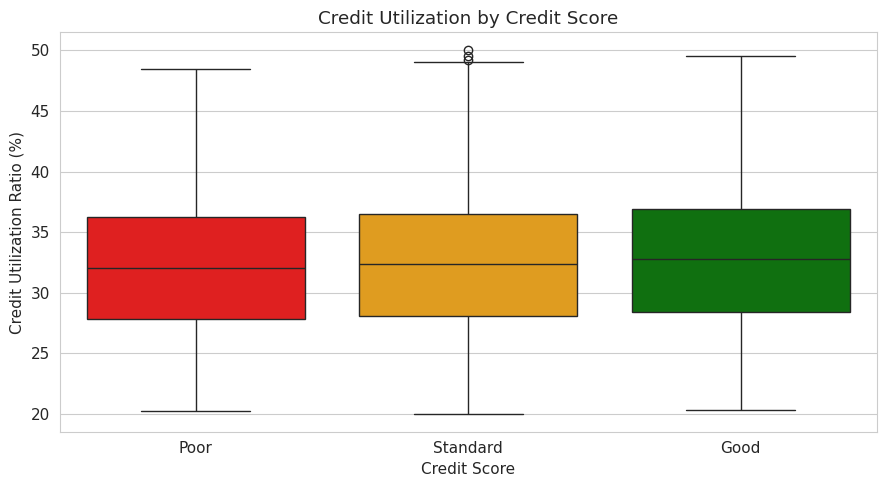

              median   mean
Credit_Score               
Good           32.74  32.69
Poor           32.01  31.99
Standard       32.33  32.31

Correlation with the credit score level : 0.046
Range of the column                    : 20.0 to 50.0
Share of records above 30%             : 63.64%
Records counted as IQR outliers        : 4


In [ ]:
# Chart - 6 : credit utilization for each credit score group
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Credit_Score', y='Credit_Utilization_Ratio',
            order=['Poor', 'Standard', 'Good'],
            hue='Credit_Score', hue_order=['Poor', 'Standard', 'Good'],
            palette=['red', 'orange', 'green'], legend=False)
plt.title('Credit Utilization by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Credit Utilization Ratio (%)')
plt.tight_layout()
plt.show()

print(df.groupby('Credit_Score')['Credit_Utilization_Ratio'].agg(['median', 'mean']).round(2))
print('')
print('Correlation with the credit score level : {:.3f}'.format(
      df['Credit_Utilization_Ratio'].corr(df['Credit_Score_Level'])))
print('Range of the column                    : {:.1f} to {:.1f}'.format(
      df['Credit_Utilization_Ratio'].min(), df['Credit_Utilization_Ratio'].max()))
print('Share of records above 30%             : {:.2f}%'.format(
      (df['Credit_Utilization_Ratio'] > 30).mean() * 100))
print('Records counted as IQR outliers        :',
      outliers.loc[outliers['Column'] == 'Credit_Utilization_Ratio', 'Outliers'].values[0])


#### **1. Why did you pick the specific chart?**

A boxplot answers a yes-or-no question very quickly: does the distribution move when the category changes? If the three boxes sit on top of each other, the column does not separate the groups, and if they are apart, it does. I expected this chart to be the strongest one in the notebook, because "keep utilization under 30%" is the most repeated rule in retail credit, so I wanted the comparison on the page.

#### **2. What is/are the insight(s) found from the chart?**

- The medians are **32.01 for Poor, 32.33 for Standard and 32.74 for Good**. The whole spread is **0.73 percentage points**.
- The correlation with the credit score is **+0.046**, which is indistinguishable from zero.
- The column only runs from 20 to 50, and it holds **100,000 different values** inside that narrow band.
- **63.6% of the records are above 30%**, so the usual rule would fire on almost two-thirds of the file.
- Only **4 records** are IQR outliers, and the middle halves of all three groups sit between 28 and 36.
- This is the opposite of what the rule of thumb predicts. In this file, utilization and credit score are unrelated.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

The positive side is that this removes a tempting rule before it is built. A bank that alerted every customer above 30% utilization would contact **63.6% of its book** and would not have separated a single good customer from a bad one, because the Good group sits at 32.74, slightly above the Poor group. Not building that rule saves the contact cost and avoids annoying low-risk customers.

The negative side is subtler. If a credit policy already uses utilization, this file can neither confirm nor reject it, because the column here does not behave like a real utilization measure. The dangerous move is to keep the column in a scorecard because it "sounds right" and let the model assign it importance it has not earned. The honest conclusion is that utilization is a monitoring metric in this data, not a risk signal, and any future model should test it rather than assume it.


### Chart - 7 **Payment Behaviour by Credit Score (Bivariate)**


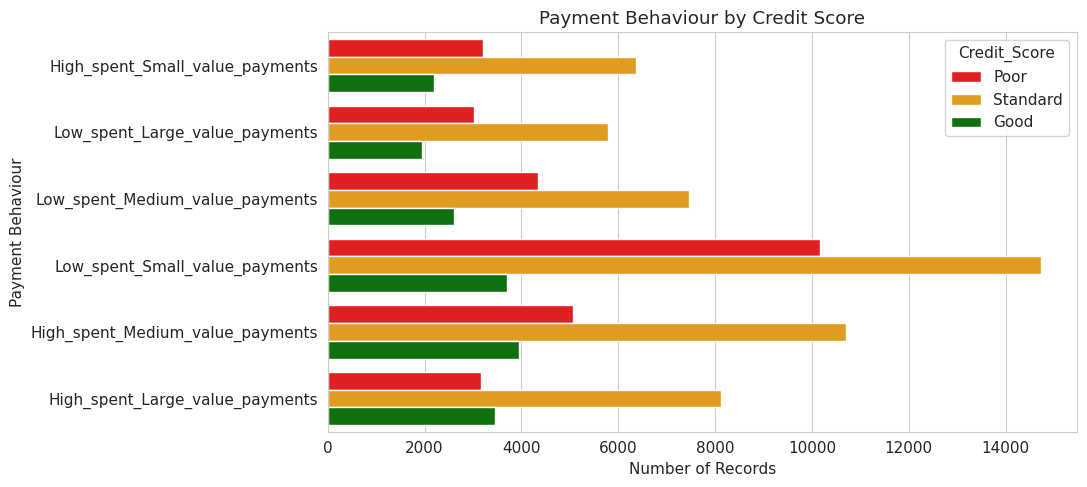

Payment_Behaviour
Low_spent_Small_value_payments      28616
High_spent_Medium_value_payments    19738
High_spent_Large_value_payments     14726
Low_spent_Medium_value_payments     14399
High_spent_Small_value_payments     11764
Low_spent_Large_value_payments      10757
Name: count, dtype: int64

Credit_Score                      Good  Poor  Standard
Payment_Behaviour                                     
High_spent_Large_value_payments   23.4  21.5      55.1
High_spent_Medium_value_payments  20.0  25.7      54.3
High_spent_Small_value_payments   18.6  27.3      54.1
Low_spent_Large_value_payments    18.0  28.1      53.8
Low_spent_Medium_value_payments   18.0  30.2      51.8
Low_spent_Small_value_payments    12.9  35.6      51.5


In [ ]:
# Chart - 7 : payment behaviour against credit score
plt.figure(figsize=(11, 5))
sns.countplot(data=df, y='Payment_Behaviour', hue='Credit_Score',
              hue_order=['Poor', 'Standard', 'Good'],
              palette=['red', 'orange', 'green'])
plt.title('Payment Behaviour by Credit Score')
plt.xlabel('Number of Records')
plt.ylabel('Payment Behaviour')
plt.tight_layout()
plt.show()

print(df['Payment_Behaviour'].value_counts())
print('')
print((pd.crosstab(df['Payment_Behaviour'], df['Credit_Score'], normalize='index') * 100).round(1))


#### **1. Why did you pick the specific chart?**

`Payment_Behaviour` has six long names such as `Low_spent_Small_value_payments`, so I turned the chart sideways. On a vertical chart those labels would overlap or have to be rotated, and rotated labels are hard to read. The horizontal bars keep the names flat, and `hue` splits each bar into the three score groups. I also printed the row percentages, because the six groups are very different in size and the raw bars hide that.

#### **2. What is/are the insight(s) found from the chart?**

- The largest group is **`Low_spent_Small_value_payments` with 28,616 records (28.6%)**. Inside it, **35.6% are Poor and only 12.9% are Good**.
- The best group is **`High_spent_Large_value_payments` with 14,726 records (14.7%)**. There **23.4% are Good and 21.5% are Poor**.
- The Good share climbs steadily from **12.9% in the worst group to 23.4% in the best one**, a spread of **10.5 percentage points**.
- The Poor share moves the other way, from **21.5% to 35.6%**.
- The pattern is consistent in both directions: the high-spend groups do better than the low-spend groups, and inside each spend level the Large payment group does better than the Small one.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

The useful part is that this column needs no new data. The platform already knows how much a customer spends and in what size, so the pattern can be used immediately, for example to decide who receives a payment reminder and who receives an upgrade offer.

The mistake to avoid is treating small spending as a bad sign on its own. A careful saver who spends in small amounts and pays in full is a good customer, yet this group has **2.8 times** the Poor share of the large spenders. If the bank used this column as a rejection rule, it would push away reliable low-value customers and lose the deposits and repayments that come with them. The signal is also weak next to `Credit_Mix`, which separates the ends by more than 40 points, so payment behaviour belongs in campaign targeting and not in the decision itself.


### Chart - 8 **Monthly Balance and Good Score Share by Month (Bivariate)**


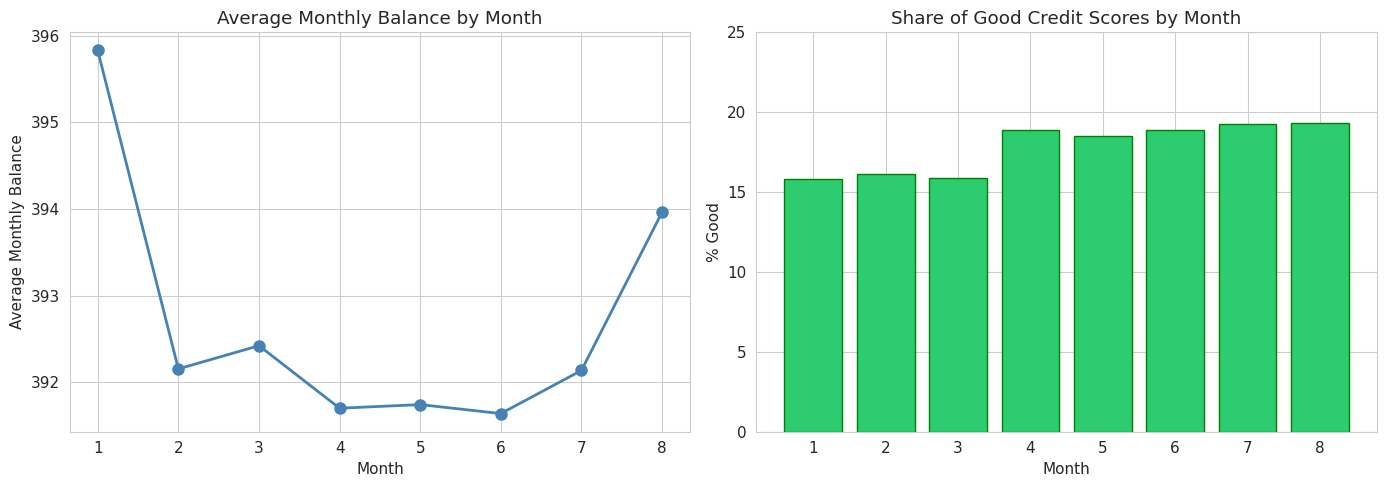

Average monthly balance by month
Month
1    395.83
2    392.15
3    392.42
4    391.70
5    391.74
6    391.64
7    392.14
8    393.96

Share of Good scores by month
Month
1    15.80
2    16.13
3    15.87
4    18.86
5    18.48
6    18.90
7    19.29
8    19.30

Balance range across the 8 months : 4.19
Change in the Good share, month 1 to month 8 : +3.50 points


In [ ]:
# Chart - 8 : two monthly trends, one on each panel
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

monthly_balance = df.groupby('Month')['Monthly_Balance'].mean()
axes[0].plot(monthly_balance.index, monthly_balance.values, 'o-',
             color='steelblue', linewidth=2, markersize=8)
axes[0].set_title('Average Monthly Balance by Month')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Average Monthly Balance')

monthly_good = df.groupby('Month')['Credit_Score'].apply(lambda s: (s == 'Good').mean() * 100)
axes[1].bar(monthly_good.index, monthly_good.values, color='#2ecc71', edgecolor='green')
axes[1].set_title('Share of Good Credit Scores by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('% Good')
axes[1].set_ylim(0, 25)

plt.tight_layout()
plt.show()

print('Average monthly balance by month')
print(monthly_balance.round(2).to_string())
print('')
print('Share of Good scores by month')
print(monthly_good.round(2).to_string())
print('')
print('Balance range across the 8 months : {:.2f}'.format(
      monthly_balance.max() - monthly_balance.min()))
print('Change in the Good share, month 1 to month 8 : {:+.2f} points'.format(
      monthly_good.loc[8] - monthly_good.loc[1]))


#### **1. Why did you pick the specific chart?**

Two questions need two panels. On the left, a line is right for a level that might drift, because the eye follows a line better than a row of bars. On the right, the share of Good scores is a percentage of a fixed 12,500 customers, so a bar makes the comparison between months direct. The right axis is fixed at 0 to 25 on purpose: if it started at 14, a 3-point move would look like the chart had doubled.

#### **2. What is/are the insight(s) found from the chart?**

- The average monthly balance is flat: **391.6 to 395.8**, a range of **4.2** across eight months, with no direction.
- The Good share is **15.80% in month 1** and **19.30% in month 8**, a rise of **3.50 percentage points**.
- The rise is not gradual. It is **15.80 → 16.13 → 15.87** for the first three months, then **18.86** in month 4 and between 18.5 and 19.3 after that. The movement is a **step between month 3 and month 4**, not a trend.
- So one half of the chart is flat and the other half steps up once.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

In a good way, this is the shape a monthly dashboard should have. Two numbers, eight points each, and a reader can see at a glance whether the portfolio is steady or moving. Building the same two panels from the same definitions every month costs almost nothing.

The negative side is the interpretation. A 3.5-point step in a file where **salary, outstanding debt and interest rate never change for a customer** is not evidence that a program worked. The columns that would explain a real improvement do not move at all, so the step has to be treated as an artefact of how the file was built until someone proves otherwise. Reading it as campaign success is the classic mistake with this kind of chart, and the cost is a budget renewed for a program that did nothing. Eight months is also too short to separate a step from a trend.


### Chart - 9 **Correlation between the Numeric Columns (Multivariate)**


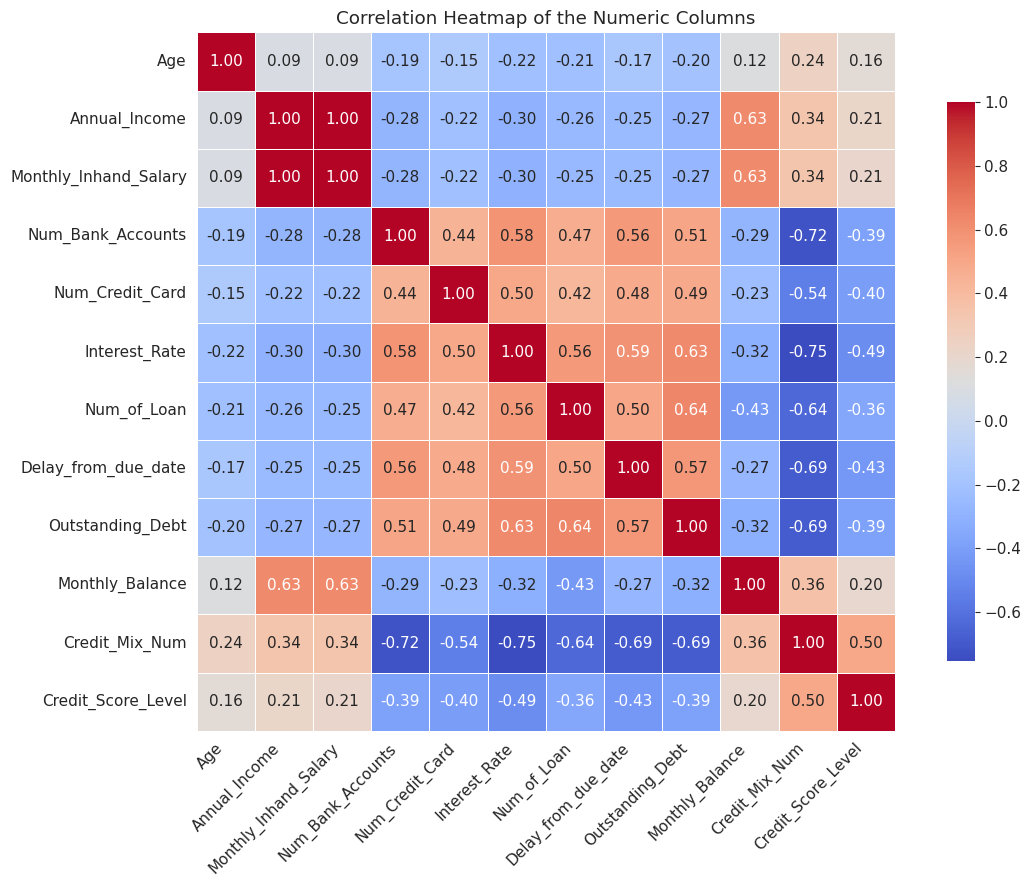

Interest_Rate           -0.485
Delay_from_due_date     -0.431
Num_Credit_Card         -0.404
Num_Bank_Accounts       -0.388
Outstanding_Debt        -0.387
Num_of_Loan             -0.358
Age                      0.160
Monthly_Balance          0.198
Monthly_Inhand_Salary    0.210
Annual_Income            0.213
Credit_Mix_Num           0.499
Credit_Score_Level       1.000

Annual income vs monthly salary : 0.998


In [ ]:
# Chart - 9 : correlation heatmap
cols = ['Age', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
        'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date',
        'Outstanding_Debt', 'Monthly_Balance', 'Credit_Mix_Num', 'Credit_Score_Level']

plt.figure(figsize=(12, 9))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap of the Numeric Columns')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(df[cols].corr()['Credit_Score_Level'].sort_values().round(3).to_string())
print('')
print('Annual income vs monthly salary : {:.3f}'.format(
      df['Annual_Income'].corr(df['Monthly_Inhand_Salary'])))


#### **1. Why did you pick the specific chart?**

A heatmap shows the correlation between many columns in one picture, so twelve columns can be compared without drawing twelve separate scatter plots. The colour makes the strong cells easy to find and the number inside each cell gives the exact value. The last column and last row hold the correlation of every column with the credit score, which is the row I was interested in. I chose the twelve columns by hand to avoid two kinds of noise: identifiers that carry no meaning, and near-duplicates that would repeat the same signal.

#### **2. What is/are the insight(s) found from the chart?**

These are the columns that move with `Credit_Score`, from strongest to weakest:

| Column | Correlation |
|---|---|
| `Credit_Mix_Num` | **+0.50** |
| `Interest_Rate` | **−0.49** |
| `Delay_from_due_date` | **−0.43** |
| `Num_Credit_Card` | −0.40 |
| `Num_Bank_Accounts` | −0.39 |
| `Outstanding_Debt` | −0.39 |
| `Num_of_Loan` | −0.36 |
| `Annual_Income` | +0.21 |
| `Monthly_Inhand_Salary` | +0.21 |
| `Monthly_Balance` | +0.20 |
| `Age` | +0.16 |

- `Credit_Mix` is the strongest column at **+0.50**, and `Interest_Rate` is almost as strong with the opposite sign at **−0.49**.
- `Credit_Utilization_Ratio` (**+0.05**) and `Total_EMI_per_month` (**+0.02**) are not in the table because they carry no signal at all.
- `Annual_Income` and `Monthly_Inhand_Salary` correlate with each other at **0.998**. They are the same column in two units.
- The five count columns are correlated between **0.42 and 0.60** with each other, so they partly measure the same thing: how many credit products a customer holds.
- Income is only +0.21 against the score, much lower than most people expect.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

The heatmap gives a short list of columns worth collecting and checking. `Credit_Mix`, `Interest_Rate`, `Delay_from_due_date` and `Outstanding_Debt` are all already on the application, so a scorecard can be built on data the platform already holds, with no purchase of external data and no new form fields.

The problem is duplication. Because `Annual_Income` and `Monthly_Inhand_Salary` carry the same information at 0.998, keeping both adds nothing and makes the result harder to explain. The same happens in a milder way with the count columns, which sit between 0.42 and 0.60 with each other. A model fed all of them will spread its weight across near-duplicates, and the explanation of the score becomes unstable. So the column list should be trimmed before modelling, and the two weak columns should be dropped rather than hoped into usefulness.


### Chart - 10 **One Name with More Than One SSN (Multivariate)**


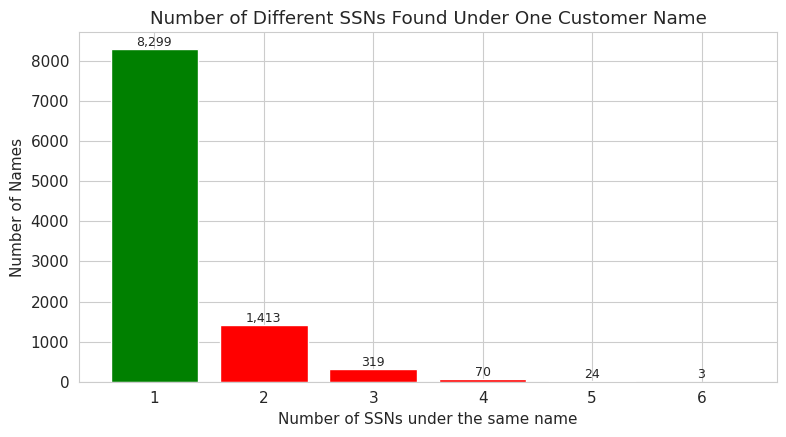

SSN
1    8299
2    1413
3     319
4      70
5      24
6       3
Name: count, dtype: int64

Different names in the data    : 10128
Different SSNs in the data     : 12500
Names with more than one SSN   : 1829
As a share of all names        : 18.1%

Customers behind those names   : 4201
Rows affected                  : 33608
As a share of the whole file   : 33.6%
Most SSNs found under one name : 6


In [ ]:
# Chart - 10 : how many different SSNs appear under the same name
ssn_per_name = identity.groupby('Name')['SSN'].nunique()
counts = ssn_per_name.value_counts().sort_index()

plt.figure(figsize=(8, 4.5))
bars = plt.bar(counts.index.astype(str), counts.values,
               color=['green'] + ['red'] * (len(counts) - 1))
plt.title('Number of Different SSNs Found Under One Customer Name')
plt.xlabel('Number of SSNs under the same name')
plt.ylabel('Number of Names')

for bar, value in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value + 80, '{:,}'.format(value),
             ha='center', fontsize=9)

plt.tight_layout()
plt.show()

print(counts)
print('')
print('Different names in the data    :', len(ssn_per_name))
print('Different SSNs in the data     :', identity['SSN'].nunique())
print('Names with more than one SSN   :', (ssn_per_name > 1).sum())
print('As a share of all names        : {:.1f}%'.format((ssn_per_name > 1).mean() * 100))

multi = ssn_per_name[ssn_per_name > 1].index
rows_affected = df['Name'].isin(multi).sum()

print('')
print('Customers behind those names   :',
      identity[identity['Name'].isin(multi)]['Customer_ID'].nunique())
print('Rows affected                  :', rows_affected)
print('As a share of the whole file   : {:.1f}%'.format(rows_affected / len(df) * 100))
print('Most SSNs found under one name :', counts.index.max())


#### **1. Why did you pick the specific chart?**

A simple bar chart is enough here, because the point is the shape and not one number. One tall green bar at "1 SSN" shows the normal case, and the short red bars stretching to 6 show the names that do not fit the normal case. A sentence like "1,829 names are duplicated" is easy to ignore; the shape makes it look like a pattern. This is also the chart that justifies keeping `Name` and `SSN` in a separate table at the start of Section 3, because they are the only columns where an identity problem can appear.

#### **2. What is/are the insight(s) found from the chart?**

- There are **10,128 different names** but **12,500 different SSNs** and 12,500 customer records.
- **1,829 names, which is 18.1% of all names, appear with more than one SSN**: 1,413 names have 2, 319 have 3, 70 have 4, 24 have 5 and 3 names have 6.
- Those names sit behind **4,201 customer records** and **33,608 rows**, which is **33.6% of the whole file**.
- The same names are the only ones shared by more than one `Customer_ID`, so both identity columns tell the same story: one name, several identities, several credit files.

#### **3. Will the gained insights help creating a positive business impact?**
**Are there any insights that lead to negative growth? Justify with specific reason.**

This is the only fraud-shaped signal in the data and it costs nothing to run. It needs no model and no new column. The rule is one line: check whether this name already exists with a different SSN. That check can run on every application before money is approved, and it catches a kind of problem a credit score can never catch, because a credit score describes how someone repaid and not who they are.

The honest caveat is that in this file the pattern may not be fraud at all. The data looks generated, so 1,829 names with several SSNs is probably a side effect of how the file was built rather than 1,829 real people. That means the deliverable is the **check**, not the names. It should flag an application for manual review and should not reject anyone automatically, because names repeat by chance and a genuine customer with a common name would be blocked for no reason.


# **5. Solution to Business Objective**


#### What do you suggest the client to achieve Business Objective?
Explain Briefly.


There are six things I would suggest, and the order matters.

**1. Build the score on the four columns that already separate the grades.**
`Credit_Mix` (+0.50), `Interest_Rate` (−0.49), `Delay_from_due_date` (−0.43) and `Outstanding_Debt` (−0.39) are the strongest columns in the file, and all four are already captured on the application form. `Credit_Mix` should come first because it is the cheapest to read and it separates the two ends by more than 40 percentage points on its own: customers with a Bad mix are 60.1% Poor and only 1.5% Good.

**2. Do not build a rule on credit utilization or EMI.**
Utilization runs from 32.01 (Poor) to 32.74 (Good), a spread of 0.73 points, with a correlation of +0.05. EMI has a correlation of +0.02. A "30% utilization" alert would fire on 63.6% of the file and would not separate anybody. These are monitoring metrics in this data, not risk signals, and treating them as signals would add noise to the score and cost to the contact centre.

**3. Use the delay column for early action.**
The median delay is **27 days for Poor, 18 for Standard and 10 for Good**, and the Poor group has a tail that reaches 62 days. A delay is measured in days, so it moves before a default does. An alert somewhere between 15 and 20 days lets the collections team call while the account can still be saved. It should be read together with `Num_of_Delayed_Payment`, because one column gives the size of the delay and the other gives how often it happened.

**4. Fix the two impossible values at the source.**
**5,868 rows have an age below 18** and **11,824 rows have a credit history longer than the person has been alive** (the longest is 404 months for a 25-year-old). No model can repair these afterwards. The rules that generate them should be corrected before the data is used again, and until then the affected rows should be excluded from any lending decision.

**5. Run the identity check before any approval.**
**1,829 names (18.1%) appear with between 2 and 6 SSNs**, and those names cover **33.6% of the rows**. The check is a single join on `Name` and `SSN`, it needs no model, and it flags the one problem a credit score cannot see. It should send the application for manual review, not reject it.

**6. Take the score over several months, not one.**
**58.3% of the customers change their credit score at least once** in eight months, and most of the predictive columns do not change at all in that time. A single month is therefore a weak reading. The most common score across two or three months is a more stable target, and it costs nothing because the history is already stored.

### What the business can do with this analysis

The business objective was to know which customers carry which risk, and this notebook answers that in a form that can be used on Monday morning. The four strongest columns are already on the application, so the score needs no new data. The size of the opportunity is known: **82.2% of the records are not Good**, and the middle group is the cheapest place to move customers because it is the largest.

What the analysis cannot do is approve a loan. It reports what separates the groups and how strongly, but it does not fit a model, does not validate one, and does not measure how much a score would improve a lending decision. Those are the next steps, and they need a proper customer-level train and test split.


### Executive Summary - Key Metrics


In [ ]:
corr_cols = ['Age', 'Annual_Income', 'Interest_Rate', 'Delay_from_due_date',
             'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_Mix_Num']
score_corr = df[corr_cols + ['Credit_Score_Level']].corr()['Credit_Score_Level']
score_corr = score_corr.drop('Credit_Score_Level')
strongest = score_corr.abs().idxmax()

summary = pd.DataFrame({
    'KPI': [
        'Total records',
        'Unique customers',
        'Months covered',
        'Average age (years)',
        'Median annual income',
        'Average annual income',
        'Average monthly in-hand salary',
        'Average credit utilization (%)',
        'Average debt-to-income ratio',
        'Average loans per customer',
        'Average interest rate (%)',
        'Average EMI burden (% of salary)',
        'Average delayed payments',
        'Average delay from due date (days)',
        'Records with a credit inquiry (%)',
        'Records paying only the minimum (%)',
        'Good credit score (%)',
        'Standard credit score (%)',
        'Poor credit score (%)',
        'Strongest column vs score',
        'Rows with at least one outlier',
        'Names with more than one SSN',
    ],
    'Value': [
        '{:,}'.format(len(df)),
        '{:,}'.format(df['Customer_ID'].nunique()),
        '8 (months 1 to 8)',
        '{:.1f}'.format(df['Age'].mean()),
        '{:,.2f}'.format(df['Annual_Income'].median()),
        '{:,.2f}'.format(df['Annual_Income'].mean()),
        '{:,.2f}'.format(df['Monthly_Inhand_Salary'].mean()),
        '{:.2f}'.format(df['Credit_Utilization_Ratio'].mean()),
        '{:.4f}'.format(df['Debt_to_Income'].mean()),
        '{:.2f}'.format(df['Num_of_Loan'].mean()),
        '{:.2f}'.format(df['Interest_Rate'].mean()),
        '{:.2f}'.format(df['EMI_Burden_Ratio'].mean() * 100),
        '{:.2f}'.format(df['Num_of_Delayed_Payment'].mean()),
        '{:.2f}'.format(df['Delay_from_due_date'].mean()),
        '{:.1f}'.format((df['Num_Credit_Inquiries'] > 0).mean() * 100),
        '{:.1f}'.format((df['Payment_of_Min_Amount'] == 'Yes').mean() * 100),
        '{:.1f}'.format((df['Credit_Score'] == 'Good').mean() * 100),
        '{:.1f}'.format((df['Credit_Score'] == 'Standard').mean() * 100),
        '{:.1f}'.format((df['Credit_Score'] == 'Poor').mean() * 100),
        '{} ({:+.2f})'.format(strongest, score_corr[strongest]),
        '{:,} ({:.1f}%)'.format(flag.sum(), flag.mean() * 100),
        '{:,} ({:.1f}%)'.format((ssn_per_name > 1).sum(), (ssn_per_name > 1).mean() * 100),
    ]
})

print('=' * 64)
print('  EXECUTIVE SUMMARY - KEY METRICS')
print('=' * 64)
display(summary)



  EXECUTIVE SUMMARY - KEY METRICS


,KPI,Value
0,Total records,"100,000"
1,Unique customers,"12,500"
2,Months covered,8 (months 1 to 8)
3,Average age (years),33.3
4,Median annual income,"36,999.71"
5,Average annual income,"50,505.12"
6,Average monthly in-hand salary,"4,197.27"
7,Average credit utilization (%),32.29
8,Average debt-to-income ratio,0.0607
9,Average loans per customer,3.53


# **Conclusion**


## Key Insights from Analysis

**Standard is the biggest group and Good is the smallest.** Standard holds 53.2% of the records, Poor 29.0% and Good only 17.8%. So the bank has a small number of low-risk customers, and those are the ones worth protecting with better rates and pre-approved offers.

**Credit Mix is the strongest single column.** Customers with a Bad mix are 60.1% Poor and only 1.5% Good, while customers with a Good mix are 48.9% Good and 16.0% Poor. That is a gap of more than 40 percentage points from one column that is already on the application form.

**Interest rate and payment delay separate the groups most cleanly.** The median interest rate is 21% for Poor and 7% for Good. The median delay is 27 days for Poor and 10 days for Good. Both columns are already stored, and the delay is the better one for early action because it is counted in days.

**Outstanding debt moves with the score as well.** The median is 1,945 for a Poor customer and 736 for a Good one, so the Poor group owes about 2.6 times as much. The count columns (cards, accounts, loans) move with the score too, between −0.36 and −0.40.

**Income matters, but much less than expected.** A Good customer earns 44,928 at the median and a Poor customer 32,065, which is 1.4 times more, but the boxes overlap heavily, so income alone cannot decide a score. Age is even weaker at +0.16.

**Occupation is not useful at all.** The best and the worst occupation differ by 7.1% on average income, while incomes inside a single occupation vary by around 38,289, which is 11 times the gap between the averages. In this file the Doctor median is below the overall median.

**Credit utilization carries no signal, which contradicts the usual rule.** The medians are 32.01 (Poor), 32.33 (Standard) and 32.74 (Good), a spread of 0.73 points, with a correlation of +0.05. EMI is just as flat at +0.02. A 30% alert would fire on 63.6% of the file without separating anyone.

**Annual Income and Monthly In-hand Salary are the same column twice.** Their correlation is 0.998, so one of them should be dropped before any modelling.

**The IQR check found outliers but no errors.** 22,919 rows (22.9%) have at least one outlier, all of them on the high side, and six of the fifteen numeric columns have none. They were kept because a high income or a large loan is a real customer and not a mistake.

**The data has two impossible values.** 5,868 rows have an age below 18 and 11,824 rows have a credit history longer than the person has been alive. Both were reported rather than deleted.

**The only fraud signal is in the two columns that look harmless.** 1,829 names, which is 18.1% of all names, appear with between 2 and 6 SSNs, and those names sit behind 33.6% of the rows. A one-line identity check catches this and needs no model.

**The file looks generated in the places that matter.** Annual income, outstanding debt and interest rate never change for a customer across the eight months, while utilization holds 100,000 distinct values inside a 20-to-50 range. Any conclusion that depends on those columns moving over time cannot be supported.


## Business Recommendations

1. **Credit-boost program for the middle group.** Target the 82.2% of records that are not Good, starting with the 53.2% in Standard:
   - payment reminders tied to the delay column, triggered at 15 to 20 days
   - a starter or small-limit product for customers with a thin file
   - pre-approved upgrades for the 17.8% who are already Good, who are the cheapest customers to keep

2. **Segmented product design.**
   - *Upper income (>100K):* premium cards, lower rates, higher limits
   - *Mid income (50K–100K):* standard products with flexible EMI
   - *Low income (<25K):* micro-loans and savings-linked credit, sized from the median and not from the mean

3. **Use occupation for marketing, not for risk.** The gap between occupations is 7.1% while the spread inside one occupation is about 38,289, so occupation should not set a limit or a risk weight. It can still choose the wording of a campaign.

4. **Monthly dashboard.** Track the same six numbers on every refresh: % Good / Standard / Poor, median delay, average debt-to-income, average EMI burden, records with an inquiry, and the share of records with a missing or impossible value.

5. **Identity and data-quality monitoring.**
   - flag any name that already exists with a different SSN, before approval
   - flag more than 15 credit inquiries (the IQR limit is 15.5, and 787 rows sit above it)
   - block any record with an age below 18 or a credit history longer than the customer's life

6. **Pricing review for the Poor group.** The median rate is 21% for Poor against 7% for Good. A customer who is already behind on payments will find 21% harder to repay than 7%, so a repayment plan or a consolidation loan usually works better for that group than a higher rate.


## Limitations

1. The credit score is not fixed for one customer. 58.3% of them change score during the 8 months, so one row is one month and not a verdict on a person.
2. The data looks generated. `Annual_Income`, `Outstanding_Debt` and `Interest_Rate` never change for a customer across the eight months, while `Credit_Utilization_Ratio` holds 100,000 distinct values inside a 20-to-50 range. Real bank data does not behave like this.
3. `Type_of_Loan` was not used. It holds 6,261 different combinations of loan types and would need to be split into separate Yes/No columns first.
4. There is no geography, gender or employment-length data, so fairness across groups could not be tested.
5. Outliers were kept and not capped, so any average in this notebook is pulled up by the high values. The medians are not affected.
6. This notebook is an EDA and not a model. The correlations show what is associated with the score; they do not show what would happen if a bank acted on it.
7. The fraud finding may not be real fraud. The repeated names are probably a side effect of how the file was built, so the check is the useful part and not the specific names.

## Next Steps

1. Correct the two impossible values at the source, so that no customer is below 18 and no credit history is longer than the customer's age.
2. Split `Type_of_Loan` into separate Yes/No columns and test whether the loan types add anything beyond the number of loans.
3. Use the most common score across three months as the target, so the label is stable and the model describes a customer rather than a month.
4. Build a model with a **customer-level split**, not a row-level one. Because each customer appears 8 times, a row-level split would put the same person in both train and test and inflate the score.
5. Add the identity check as a fixed step in the loan process, before the score is calculated.
6. Collect data that moves month to month (salary, debt, per-account utilization). A real early-warning system needs columns that change before the customer does.


## Final Summary

| Question | Answer |
|---|---|
| What is the target? | `Credit_Score`, with Good, Standard and Poor |
| How big is each group? | Standard 53.2%, Poor 29.0%, Good 17.8% |
| Which columns matter most? | `Credit_Mix`, `Interest_Rate`, `Delay_from_due_date`, `Outstanding_Debt` |
| Which columns matter least? | `Occupation`, `Credit_Utilization_Ratio`, `Total_EMI_per_month`, `Age` |
| Are there outliers? | Yes, 22.9% of rows, all on the high side. Kept on purpose |
| Is there a fraud signal? | One: 18.1% of names appear with 2 to 6 SSNs |
| Is the data clean? | No. No nulls and no duplicates, but two impossible values and 22.9% outlier rows |
| Is this ready for a lending decision? | No. It is an EDA and a KPI baseline, not a validated model |
| What is the biggest problem in the data? | The score changes for 58.3% of customers, and three key columns never move at all |

---

*Prepared as a student data-analytics capstone project. Every number in this notebook is computed from the 100,000-record Paisabazaar dataset in the same folder.*
